# 1. Assignment -9- 
— Text Analysis with IMDb Reviews

### 2. Context & Scenario

You are part of a machine learning systems team supporting a media platform that wants to analyze large volumes of user reviews for product and content decisions. Leadership needs a reproducible notebook that can validate raw review text, build defensible sentiment models, and summarize major themes in customer feedback. Your task is to treat text analysis as a full pipeline rather than a single model: data validation, feature construction, baseline and improved modeling, diagnostics, and reporting. The work must also address operational concerns such as leakage prevention, reproducibility, vocabulary drift, performance monitoring, and rollback planning.

### 3. Dataset

- **Dataset name:** IMDb Large Movie Review Dataset  
- **Access links:**  
  - Dataset page: `https://ai.stanford.edu/~amaas/data/sentiment/`  
  - Direct download: `https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz`  
- **Description:** This dataset contains raw movie reviews labeled for binary sentiment (`pos`, `neg`). The unit of analysis is a full review document, and the corpus includes approximately 50,000 labeled reviews, typically split into training and test sets. Reviews are substantially longer than sentence-level benchmark datasets, making them suitable for studying preprocessing, sparse feature construction, sentiment classification, and unsupervised topic discovery.  

### 4. Machine Learning Tasks

- Implement a reproducible text-analysis workflow in Jupyter that runs end-to-end in order.
- Validate the corpus using schema checks, missingness checks, duplicate audits, text-length profiling, and guardrail assertions.
- Construct Bag-of-Words and TF–IDF features, inspect the effect of n-grams, and generate required matplotlib plots.
- Evaluate a lexicon-based sentiment baseline, then train and compare a supervised baseline and an improved sparse text classifier.
- Include confusion matrix analysis, feature-based error analysis, and written reasoning answers in Markdown cells.
- Fit an NMF topic model and interpret topics using both top terms and exemplar reviews.
- Produce a sentiment-by-topic summary and discuss limitations, next-step experiments, and deployment concerns.
- Monitor reproducibility, leakage risk, vocabulary drift, performance regression, and rollback conditions as ML systems concerns.

### 5. Deliverables

- One executed Jupyter notebook with code, plots, and written answers embedded in Markdown cells.
- A concise interpretation of corpus quality, sentiment-model comparison, topic outputs, and sentiment-by-topic findings.
- A short systems note covering reproducibility artifacts, monitoring, drift, cost, and rollback strategy.

### 6. Grading Rubric (100 points)

| Criterion | Points | Description |
|---|---:|---|
| Code correctness and notebook execution | 25 | Notebook runs end-to-end in the intended order; code is correct, organized, and reproducible. |
| Data quality and validation | 15 | Meaningful schema checks, missingness analysis, duplicate checks, text-length profiling, and guardrails. |
| EDA and required plots | 10 | Appropriate summaries and matplotlib visualizations; observations connected to modeling choices. |
| Modeling and evaluation | 25 | Lexicon baseline evaluated; supervised baseline and improved model compared with appropriate metrics and diagnostics. |
| Interpretation and reporting | 15 | Clear interpretation of metrics, confusion matrix, error cases, topic outputs, exemplar documents, and sentiment-by-topic summary. |
| ML systems thinking | 10 | Strong discussion of reproducibility, monitoring, drift, leakage, compute cost, and rollback strategy. |
| **Total** | **100** |  |


________________________________________________________________________________________________________________________________________________

# Assignment 9
## Text Analysis with IMDb Reviews

## Context & Scenario

The goal is to build a text-analysis pipeline for movie reviews. The workflow includes data validation, sentiment models, error analysis, and topic modeling.

## Dataset

This assignment uses the IMDb Large Movie Review Dataset. The reviews are labeled as either positive or negative. The dataset is already divided into training and test sets, so I will keep that split for evaluation.

In [34]:
# Imports and reproducibility

import os
import re
import sys
import tarfile
import urllib.request
import ssl
import certifi
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.decomposition import NMF

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random seed:", RANDOM_STATE)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
pandas: 2.3.3
NumPy: 2.5.3
Random seed: 42


## Load the IMDb Dataset

The dataset is downloaded from the Stanford IMDb dataset page and extracted locally.

In [35]:
DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

DATA_DIR = "aclImdb"
ARCHIVE_NAME = "aclImdb_v1.tar.gz"

if not os.path.exists(DATA_DIR):

    if not os.path.exists(ARCHIVE_NAME):
        print("Downloading IMDb dataset...")

        ssl_context = ssl.create_default_context(
            cafile=certifi.where()
        )

        request = urllib.request.Request(
            DATA_URL,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        with urllib.request.urlopen(
            request,
            context=ssl_context
        ) as response:
            with open(ARCHIVE_NAME, "wb") as file:
                file.write(response.read())

        print("Download complete.")

    print("Extracting dataset...")

    with tarfile.open(ARCHIVE_NAME, "r:gz") as tar:
        tar.extractall(".")

    print("Extraction complete.")

else:
    print("IMDb dataset already exists.")

IMDb dataset already exists.


## Read Reviews

Each review is stored as a text file inside the positive or negative folder.

In [36]:
def load_reviews(base_path):
    texts = []
    labels = []

    for label_name, label_value in [("neg", 0), ("pos", 1)]:
        folder = os.path.join(base_path, label_name)

        for filename in os.listdir(folder):
            if filename.endswith(".txt"):
                filepath = os.path.join(folder, filename)

                with open(
                    filepath,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as file:
                    text = file.read()

                texts.append(text)
                labels.append(label_value)

    return pd.DataFrame({
        "text": texts,
        "label": labels
    })


train_df = load_reviews(
    os.path.join(DATA_DIR, "train")
)

test_df = load_reviews(
    os.path.join(DATA_DIR, "test")
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (25000, 2)
Testing shape: (25000, 2)


,text,label
0,Story of a man who has unnatural feelings for ...,0
1,Airport '77 starts as a brand new luxury 747 p...,0
2,This film lacked something I couldn't put my f...,0
3,"Sorry everyone,,, I know this is supposed to b...",0
4,When I was little my parents took me along to ...,0


## Data Validation

I check the schema, missing values, duplicates, and review lengths before modeling.

In [37]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isna().sum())

print("\nDuplicate reviews:")
print(train_df["text"].duplicated().sum())

print("\nTest duplicate reviews:")
print(test_df["text"].duplicated().sum())

print("\nLabel counts:")
print(train_df["label"].value_counts())

Training columns:
['text', 'label']

Missing values:
text     0
label    0
dtype: int64

Duplicate reviews:
96

Test duplicate reviews:
199

Label counts:
label
0    12500
1    12500
Name: count, dtype: int64


## Guardrail Checks

In [38]:
assert list(train_df.columns) == ["text", "label"]
assert list(test_df.columns) == ["text", "label"]

assert train_df["text"].notna().all()
assert test_df["text"].notna().all()

assert train_df["label"].isin([0, 1]).all()
assert test_df["label"].isin([0, 1]).all()

assert len(train_df) > 0
assert len(test_df) > 0

print("Validation checks passed.")

Validation checks passed.


## Duplicate Audit

Duplicate reviews can make evaluation overly optimistic if the same text appears in both training and testing data.

In [39]:
train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

overlap = train_texts.intersection(test_texts)

print("Exact train/test duplicate reviews:", len(overlap))

Exact train/test duplicate reviews: 123


### Duplicate Interpretation

Exact duplicate reviews between training and testing would be a leakage risk. The overlap check helps confirm whether the test set contains reviews already seen during training.

## Review Length

Review length is useful for checking the overall structure of the text data.

In [40]:
train_df["char_length"] = train_df["text"].str.len()

train_df["word_length"] = train_df["text"].str.split().str.len()

print(train_df[["char_length", "word_length"]].describe())

       char_length   word_length
count  25000.00000  25000.000000
mean    1325.06964    233.787200
std     1003.13367    173.733032
min       52.00000     10.000000
25%      702.00000    127.000000
50%      979.00000    174.000000
75%     1614.00000    284.000000
max    13704.00000   2470.000000


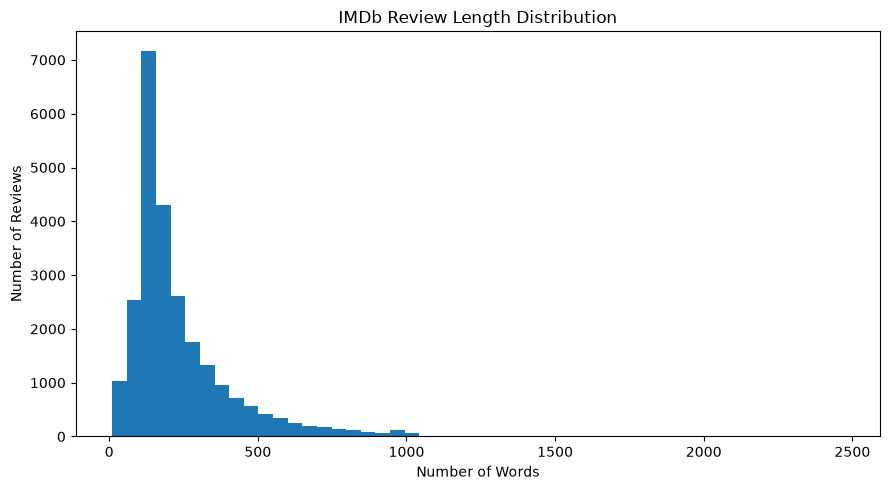

In [41]:
plt.figure(figsize=(9, 5))

plt.hist(
    train_df["word_length"],
    bins=50
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("IMDb Review Length Distribution")

plt.tight_layout()
plt.show()

### Length Interpretation

The reviews vary substantially in length. This supports using sparse text features that can handle different document sizes.

## Sentiment Distribution

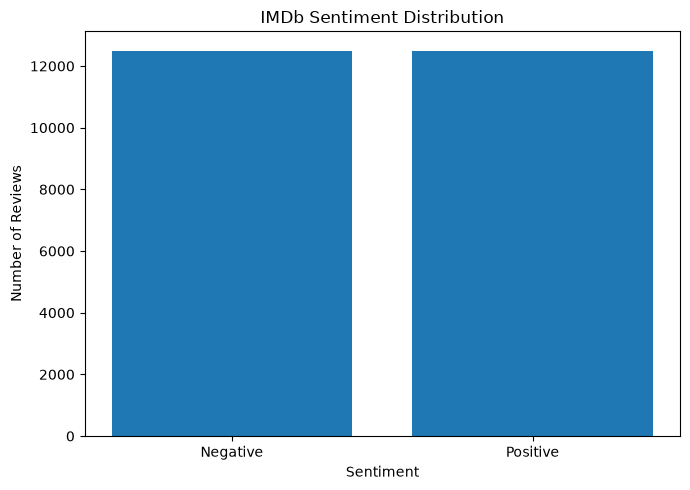

In [42]:
label_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Negative", "Positive"],
    label_counts.values
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.title("IMDb Sentiment Distribution")

plt.tight_layout()
plt.show()

## Prepare Modeling Data

The text and labels are separated from the validation columns. No text preprocessing is learned from the test set.

In [43]:
X_train_text = train_df["text"]
y_train = train_df["label"]

X_test_text = test_df["text"]
y_test = test_df["label"]

print("Training reviews:", len(X_train_text))
print("Testing reviews:", len(X_test_text))

Training reviews: 25000
Testing reviews: 25000


## Bag-of-Words Features

Bag-of-Words represents each review using word counts. The vectorizer is fit only on the training reviews to prevent vocabulary leakage.

In [44]:
bow_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_features=50000
)

X_train_bow = bow_vectorizer.fit_transform(X_train_text)
X_test_bow = bow_vectorizer.transform(X_test_text)

print("BoW training shape:", X_train_bow.shape)
print("BoW test shape:", X_test_bow.shape)

BoW training shape: (25000, 44490)
BoW test shape: (25000, 44490)


## N-Gram Comparison

I compare unigram features with unigram and bigram features. Bigrams can capture short phrases that a single word cannot represent.

In [45]:
unigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_features=50000,
    ngram_range=(1, 1)
)

bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_features=50000,
    ngram_range=(1, 2)
)

X_uni = unigram_vectorizer.fit_transform(X_train_text)
X_bi = bigram_vectorizer.fit_transform(X_train_text)

print("Unigram features:", X_uni.shape[1])
print("Unigram + bigram features:", X_bi.shape[1])

Unigram features: 44490
Unigram + bigram features: 50000


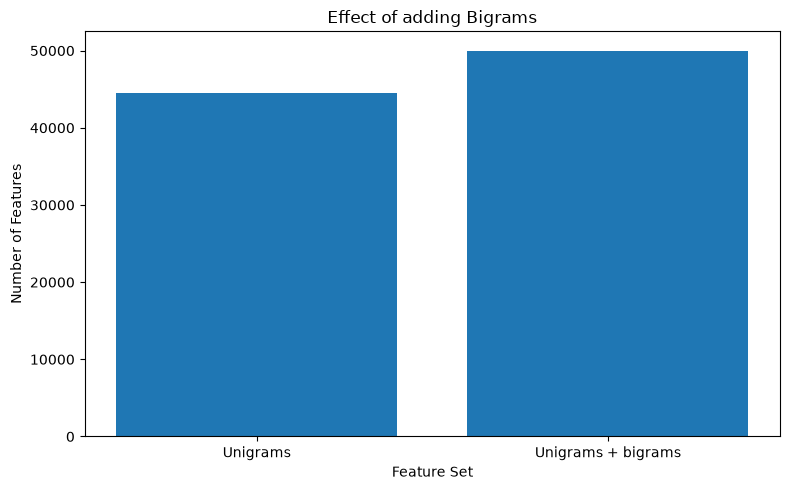

In [46]:
ngram_counts = pd.DataFrame({
    "Feature Set": [
        "Unigrams",
        "Unigrams + bigrams"
    ],
    "Number of Features": [
        X_uni.shape[1],
        X_bi.shape[1]
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    ngram_counts["Feature Set"],
    ngram_counts["Number of Features"]
)

plt.xlabel("Feature Set")
plt.ylabel("Number of Features")
plt.title("Effect of adding Bigrams")

plt.tight_layout()
plt.show()

### N-Gram Interpretation

Adding bigrams increases the number of features. This can help the model recognize phrases such as "not good" that are harder to represent with individual words alone.

## Lexicon Sentiment Baseline

VADER provides a simple sentiment baseline without training a classifier on the IMDb labels.

In [47]:
# Install/import VADER if needed

import nltk

try:
    from nltk.sentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download("vader_lexicon")
    from nltk.sentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()

print("VADER ready.")

VADER ready.


In [48]:
def vader_predict(texts):
    predictions = []

    for text in texts:
        score = sia.polarity_scores(text)["compound"]

        if score >= 0:
            predictions.append(1)
        else:
            predictions.append(0)

    return np.array(predictions)


vader_pred = vader_predict(X_test_text)

vader_accuracy = accuracy_score(
    y_test,
    vader_pred
)

vader_precision = precision_score(
    y_test,
    vader_pred,
    zero_division=0
)

vader_recall = recall_score(
    y_test,
    vader_pred,
    zero_division=0
)

vader_f1 = f1_score(
    y_test,
    vader_pred,
    zero_division=0
)

print("VADER Accuracy:", round(vader_accuracy, 4))
print("VADER Precision:", round(vader_precision, 4))
print("VADER Recall:", round(vader_recall, 4))
print("VADER F1:", round(vader_f1, 4))

VADER Accuracy: 0.6983
VADER Precision: 0.6498
VADER Recall: 0.8602
VADER F1: 0.7403


### Lexicon Baseline Interpretation

The lexicon model does not learn from the IMDb training labels. Its performance gives a useful baseline for seeing whether supervised models improve sentiment classification.

## Supervised Baseline

Logistic Regression is used with Bag-of-Words features as the supervised baseline.

In [49]:
bow_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

bow_model.fit(
    X_train_bow,
    y_train
)

bow_pred = bow_model.predict(
    X_test_bow
)

bow_prob = bow_model.predict_proba(
    X_test_bow
)[:, 1]

print(classification_report(
    y_test,
    bow_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.85      0.87      0.86     12500
           1       0.87      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



## Improved Sparse Model

The improved model uses TF-IDF with unigrams and bigrams. TF-IDF reduces the effect of very common words and gives more weight to informative terms.

In [50]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_features=75000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train_text
)

X_test_tfidf = tfidf_vectorizer.transform(
    X_test_text
)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)

TF-IDF training shape: (25000, 75000)
TF-IDF test shape: (25000, 75000)


In [51]:
tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

tfidf_model.fit(
    X_train_tfidf,
    y_train
)

tfidf_pred = tfidf_model.predict(
    X_test_tfidf
)

tfidf_prob = tfidf_model.predict_proba(
    X_test_tfidf
)[:, 1]

print(classification_report(
    y_test,
    tfidf_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.89      0.88      0.89     12500
           1       0.89      0.89      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000



## Model Comparison

The models are compared using accuracy, precision, recall, F1, and ROC-AUC.

In [52]:
model_results = pd.DataFrame({
    "Model": [
        "VADER",
        "BoW + Logistic Regression",
        "TF-IDF + Bigrams + Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, vader_pred),
        accuracy_score(y_test, bow_pred),
        accuracy_score(y_test, tfidf_pred)
    ],
    "Precision": [
        precision_score(y_test, vader_pred, zero_division=0),
        precision_score(y_test, bow_pred, zero_division=0),
        precision_score(y_test, tfidf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, vader_pred, zero_division=0),
        recall_score(y_test, bow_pred, zero_division=0),
        recall_score(y_test, tfidf_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, vader_pred, zero_division=0),
        f1_score(y_test, bow_pred, zero_division=0),
        f1_score(y_test, tfidf_pred, zero_division=0)
    ],
    "ROC_AUC": [
        np.nan,
        roc_auc_score(y_test, bow_prob),
        roc_auc_score(y_test, tfidf_prob)
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,VADER,0.69832,0.649825,0.86016,0.740343,NaN
1,BoW + Logistic Regression,0.85788,0.865035,0.84808,0.856473,0.928527
2,TF-IDF + Bigrams + Logistic Regression,0.88856,0.885476,0.89256,0.889004,0.956197


### Model Comparison Interpretation

The supervised models can learn patterns specific to the IMDb dataset, while VADER uses a general sentiment lexicon. The TF-IDF model also has access to bigrams, which can help with short phrases and sentiment expressions.

## Confusion Matrix

The confusion matrix shows where the improved model makes correct and incorrect predictions.

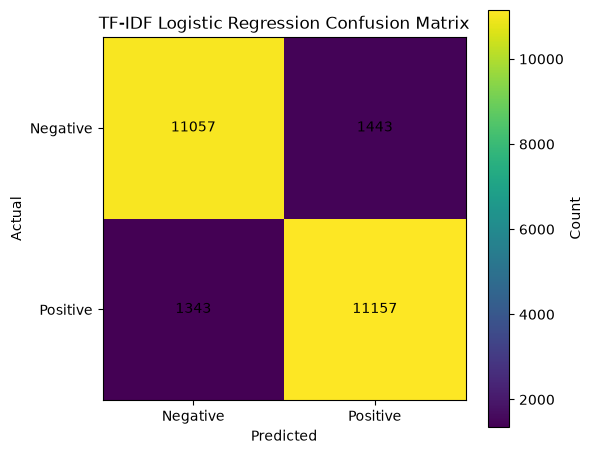

In [53]:
tfidf_cm = confusion_matrix(
    y_test,
    tfidf_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(tfidf_cm)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TF-IDF Logistic Regression Confusion Matrix")

plt.colorbar(label="Count")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            tfidf_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

### Confusion Matrix Interpretation

False positives are negative reviews classified as positive. False negatives are positive reviews classified as negative. Both errors matter because the platform wants an accurate view of overall user sentiment.

## Feature Analysis

The model coefficients show which terms are most associated with positive and negative sentiment.

In [54]:
feature_names = tfidf_vectorizer.get_feature_names_out()

coefficients = tfidf_model.coef_[0]

top_positive_indices = np.argsort(coefficients)[-20:][::-1]
top_negative_indices = np.argsort(coefficients)[:20]

top_positive = pd.DataFrame({
    "term": feature_names[top_positive_indices],
    "coefficient": coefficients[top_positive_indices]
})

top_negative = pd.DataFrame({
    "term": feature_names[top_negative_indices],
    "coefficient": coefficients[top_negative_indices]
})

print("Top positive features:")
display(top_positive)

print("Top negative features:")
display(top_negative)

Top positive features:


,term,coefficient
0,great,7.667181
1,excellent,6.728732
2,best,5.717880
3,perfect,5.142497
4,wonderful,5.126439
5,amazing,4.584952
6,favorite,4.349890
7,love,4.205611
8,fun,4.055424
9,loved,4.025737


Top negative features:


,term,coefficient
0,worst,-9.370276
1,bad,-8.210808
2,awful,-6.772205
3,boring,-6.128059
4,waste,-6.019125
5,poor,-5.716156
6,worse,-5.036139
7,terrible,-5.019780
8,dull,-4.495761
9,horrible,-4.358264


### Feature Interpretation

The strongest positive and negative features give a simple explanation of what the classifier learned. Some features may represent specific opinions, phrases, or movie-review language.

## Error Analysis

I will inspect reviews that the TF-IDF model classified incorrectly.

In [55]:
error_df = pd.DataFrame({
    "text": X_test_text.values,
    "actual": y_test.values,
    "predicted": tfidf_pred,
    "probability": tfidf_prob
})

errors = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Number of incorrect predictions:", len(errors))

display(errors.head(10))

Number of incorrect predictions: 2786


,text,actual,predicted,probability
4,Brass pictures (movies is not a fitting word f...,0,1,0.507829
9,Wealthy horse ranchers in Buenos Aires have a ...,0,1,0.517873
16,At the bottom end of the apocalypse movie scal...,0,1,0.712629
17,Earth has been destroyed in a nuclear holocaus...,0,1,0.628603
19,New York family is the last in their neighborh...,0,1,0.676795
44,This tale of the upper-classes getting their c...,0,1,0.594142
51,"This is one of those strange, self-important, ...",0,1,0.526560
55,Seeing this film for the first time twenty yea...,0,1,0.608290
56,From time to time it's very advisable for the ...,0,1,0.688481
59,CAUTION SPOILER: At the end of the movie it is...,0,1,0.724186


In [56]:
errors["confidence"] = np.abs(
    errors["probability"] - 0.5
)

uncertain_errors = errors.sort_values(
    "confidence"
).head(10)

display(
    uncertain_errors[
        [
            "actual",
            "predicted",
            "probability",
            "text"
        ]
    ]
)

,actual,predicted,probability,text
14072,1,0,0.499917,While i read all of the complaints about this ...
5946,0,1,0.500227,What could have been a good story was destroye...
1931,0,1,0.500269,A remake of a successful movie can be a tricky...
247,0,1,0.500384,Now I'm a big animation fan -- love Svankmeyer...
10237,0,1,0.500398,Joan Fontaine is swept off her feet by the sua...
24338,1,0,0.499566,too bad they showed palm trees that could not ...
1668,0,1,0.500452,"this is an alright show to watch, its not the ..."
2118,0,1,0.500455,"There is nothing like an Oscar Wilde comedy, a..."
12765,1,0,0.499518,I was peeved that the best make-up academy awa...
8559,0,1,0.500524,"Ugly, heartless Hollywood crap that expects no..."


### Error Analysis Interpretation

The uncertain errors are reviews where the model's probability is close to 0.50. These cases may contain mixed opinions, sarcasm, unusual wording, or sentiment that is difficult to capture with word-based features.

## NMF Topic Modeling

NMF is used to find common themes in the reviews without using the sentiment labels. The topic model is fit only on training reviews to avoid using test data.

In [57]:
topic_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=5,
    max_features=20000,
    ngram_range=(1, 2)
)

X_topic_train = topic_vectorizer.fit_transform(
    X_train_text
)

print("Topic matrix shape:", X_topic_train.shape)

Topic matrix shape: (25000, 20000)


In [58]:
n_topics = 8

nmf_model = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=RANDOM_STATE,
    max_iter=300
)

W_train = nmf_model.fit_transform(
    X_topic_train
)

H = nmf_model.components_

print("Document-topic shape:", W_train.shape)
print("Topic-term shape:", H.shape)

Document-topic shape: (25000, 8)
Topic-term shape: (8, 20000)


## Topic Terms

The highest-weighted terms are used to interpret each topic.

In [59]:
topic_terms = topic_vectorizer.get_feature_names_out()

for topic_index, topic_weights in enumerate(H):
    top_indices = topic_weights.argsort()[-10:][::-1]

    terms = [
        topic_terms[i]
        for i in top_indices
    ]

    print(
        f"Topic {topic_index + 1}:",
        ", ".join(terms)
    )

Topic 1: br, br br, br movie, movie br, 10, br film, br 10, film br, time br, br story
Topic 2: movie, movies, great, good, watch, story, watch movie, good movie, book, saw
Topic 3: film, films, great, good, br film, director, story, scenes, horror, characters
Topic 4: bad, acting, horror, effects, good, plot, budget, worst, terrible, special
Topic 5: story, man, life, love, young, character, family, role, does, little
Topic 6: just, like, really, don, people, think, know, funny, didn, watch
Topic 7: series, episode, episodes, tv, season, original, great, characters, tv series, book
Topic 8: seen, ve, ve seen, worst, movies, best, movie ve, worst movie, movies ve, time


In [60]:
topic_strength = W_train.mean(axis=0)

topic_summary = pd.DataFrame({
    "Topic": range(1, n_topics + 1),
    "Average Strength": topic_strength
})

topic_summary

,Topic,Average Strength
0,1,0.018039
1,2,0.013909
2,3,0.012349
3,4,0.007911
4,5,0.012965
5,6,0.010706
6,7,0.005685
7,8,0.006363


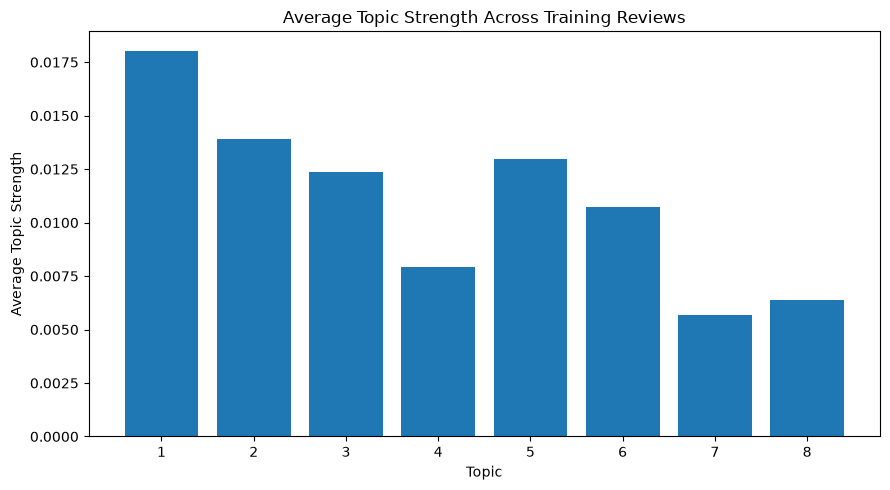

In [61]:
plt.figure(figsize=(9, 5))

plt.bar(
    topic_summary["Topic"],
    topic_summary["Average Strength"]
)

plt.xlabel("Topic")
plt.ylabel("Average Topic Strength")
plt.title("Average Topic Strength Across Training Reviews")

plt.tight_layout()
plt.show()

## Topic Exemplar Reviews

For each topic, I inspect a review with a high topic score to better understand what the topic represents.

In [62]:
for topic_index in range(n_topics):
    strongest_review = W_train[:, topic_index].argmax()

    print("================================================")
    print(f"Topic {topic_index + 1}")
    print("================================================")
    print(X_train_text.iloc[strongest_review][:1000])
    print()

Topic 1
Also known in a different form as "House of Exorcism," this messy<br /><br />little film takes itself so seriously as to kill any entertainment value<br /><br />whatsoever.<br /><br />The spare plot involves European tourist Elke Sommer who has a<br /><br />chance run in with Telly Savalas, who looks just like the devil she<br /><br />saw on a fresco in the square. Sommer is given a ride to a<br /><br />mysterious house in the country, where Savalas happens to be<br /><br />butler. There, she is mistaken for a long dead woman, and the real<br /><br />soap opera theatrics begin. The house's blind matriarch's<br /><br />husband had an affair with the dead woman, who was the<br /><br />matriarch's son's fiancee. The couple who gave Sommer the ride?<br /><br />Well, the woman is giving the chauffeur, uh, "back seat driving<br /><br />lessons," and the husband knows and does not care. Eventually,<br /><br />most of the cast is killed, Sommer is drugged and raped,<br /><br />escapes,

## Sentiment by Topic

Each review is assigned to its strongest topic. I then compare the average sentiment within each topic.

In [63]:
topic_assignments = W_train.argmax(axis=1)

topic_sentiment_df = pd.DataFrame({
    "topic": topic_assignments + 1,
    "sentiment": y_train.values
})

sentiment_by_topic = (
    topic_sentiment_df
    .groupby("topic")["sentiment"]
    .agg(
        average_sentiment="mean",
        review_count="count"
    )
    .reset_index()
)

sentiment_by_topic

,topic,average_sentiment,review_count
0,1,0.462642,6625
1,2,0.490901,4506
2,3,0.544916,4052
3,4,0.109868,1520
4,5,0.691808,4004
5,6,0.365452,1702
6,7,0.670472,1314
7,8,0.450274,1277


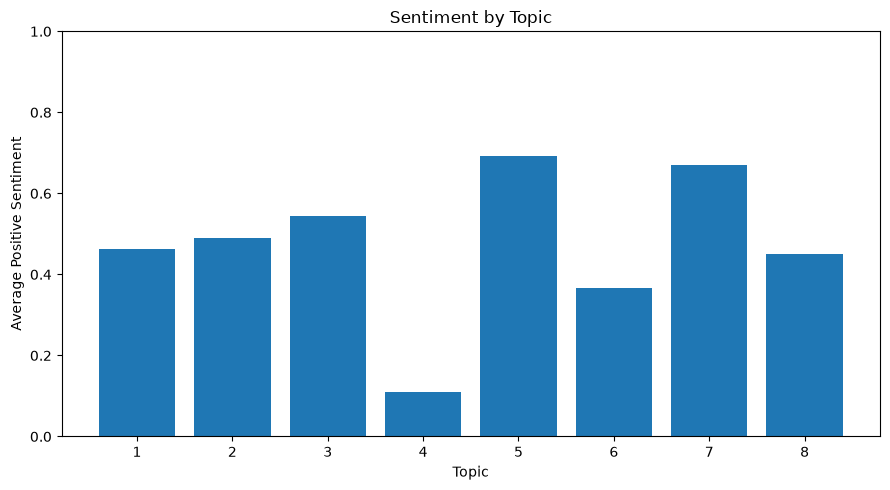

In [64]:
plt.figure(figsize=(9, 5))

plt.bar(
    sentiment_by_topic["topic"],
    sentiment_by_topic["average_sentiment"]
)

plt.xlabel("Topic")
plt.ylabel("Average Positive Sentiment")
plt.title("Sentiment by Topic")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### Sentiment-by-Topic Interpretation

Topics with higher average sentiment contain more positive reviews. Topics with lower averages contain more negative reviews. The topic labels are based on the strongest terms, so the actual meaning of each topic should be interpreted using both the terms and exemplar reviews.

## Reproducibility

I would save the dataset version, random seed, vectorizer settings, vocabulary, model parameters, topic-model settings, evaluation metrics, and software versions. This would make it easier to reproduce the same results later.

## Leakage Prevention

The vectorizers are fit only on the training reviews. The test reviews are only transformed after the vocabulary and feature settings have been learned. The NMF topic model is also fit using training reviews only.

## Vocabulary Drift

Movie language can change over time as new titles, slang, actors, and phrases appear. I would monitor the rate of unknown or new terms and changes in common word frequencies. A large change could trigger vocabulary updates or model retraining.

## Performance Monitoring

I would monitor accuracy, precision, recall, F1, and false-positive and false-negative rates. I would also track review length, vocabulary changes, prediction distributions, and topic distributions. A sustained drop in F1 or a major change in the input data would trigger an investigation.

## Compute Cost

Sparse BoW and TF-IDF models are relatively efficient for large text datasets. Bigrams increase the number of features and therefore increase memory and training time. NMF is more expensive because it repeatedly factorizes the large sparse document-term matrix.

## Rollback Plan

Each model version should store its training data version, vocabulary, parameters, metrics, and deployment date. If production performance drops below an acceptable level, the previous validated model can be restored while the new model is investigated.

## Limitations

The models rely mostly on word and phrase patterns, so they may struggle with sarcasm, context, and mixed opinions. The topic model also requires interpretation because the discovered topics do not have predefined labels. Future work could test different n-grams, stronger classifiers, word embeddings, and more advanced language models.

## Final Results Summary

The IMDb reviews were validated and converted into sparse text features. VADER provided a simple lexicon baseline, while supervised Logistic Regression models were trained using BoW and TF-IDF features. The improved model was also examined using confusion matrices, important features, and misclassified reviews. NMF was used to find major review themes, and the topics were compared with sentiment. The pipeline also considers leakage, reproducibility, vocabulary drift, monitoring, compute cost, and rollback.

In [65]:
experiment_log = pd.DataFrame({
    "Model": [
        "VADER",
        "BoW + Logistic Regression",
        "TF-IDF + Bigrams + Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, vader_pred),
        accuracy_score(y_test, bow_pred),
        accuracy_score(y_test, tfidf_pred)
    ],
    "Precision": [
        precision_score(y_test, vader_pred, zero_division=0),
        precision_score(y_test, bow_pred, zero_division=0),
        precision_score(y_test, tfidf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, vader_pred, zero_division=0),
        recall_score(y_test, bow_pred, zero_division=0),
        recall_score(y_test, tfidf_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, vader_pred, zero_division=0),
        f1_score(y_test, bow_pred, zero_division=0),
        f1_score(y_test, tfidf_pred, zero_division=0)
    ],
    "ROC_AUC": [
        np.nan,
        roc_auc_score(y_test, bow_prob),
        roc_auc_score(y_test, tfidf_prob)
    ]
})

experiment_log

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,VADER,0.69832,0.649825,0.86016,0.740343,NaN
1,BoW + Logistic Regression,0.85788,0.865035,0.84808,0.856473,0.928527
2,TF-IDF + Bigrams + Logistic Regression,0.88856,0.885476,0.89256,0.889004,0.956197
